> # Lab 9 - Charlie Caravati

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import numpy.linalg as la
import math
from scipy.integrate import quad

In [19]:
def eval_legendre(n, x):

    if n < 0:
        raise ValueError("Order n must be a non-negative integer.")
    
    p = [0.0] * (n + 1)
    
    p[0] = 1.0
    if n == 0:
        return p
        
    p[1] = x
    
    for k in range(1, n):
        p[k + 1] = (1.0 / (k + 1)) * ((2 * k + 1) * x * p[k] - k * p[k - 1])
        
    return p

In [16]:
n, x = 5, .7
results = eval_legendre(n, x)

results

[1.0,
 0.7,
 0.23499999999999988,
 -0.19250000000000012,
 -0.4120625,
 -0.3651987499999999]

Using scipy.integrate.quad, create a one line code that evaluates a coefficient aj . 

Note: you have to create a subroutine that evaluates the f(x)ϕj (x)w(x) to feed into this, and also a sub-
routine ϕ2j(x)w(x) for evaluating the normalization. You should not use any symbolic packages. 

In [55]:
def driver():

#  function you want to approximate
    f = lambda x: 1/(1+(x**2))

# Interval of interest    
    a = -1
    b = 1
# weight function    
    w = lambda x: 1.

# order of approximation
    n = 2

#  Number of points you want to sample in [a,b]
    N = 1000
    xeval = np.linspace(a,b,N+1)
    pval = np.zeros(N+1)

    for kk in range(N+1):
      pval[kk] = eval_legendre_expansion(f,a,b,w,n,xeval[kk])
      
    ''' create vector with exact values'''
    fex = np.zeros(N+1)
    for kk in range(N+1):
        fex[kk] = f(xeval[kk])
        
    plt.figure()    
    plt.plot(xeval,fex,'ro-', label= 'f(x)')
    plt.plot(xeval,pval,'bs--',label= 'Expansion') 
    plt.legend()
    plt.show()    
    
    err = abs(pval-fex)
    print("Max error:", max(err))
    plt.semilogy(xeval,err,'ro--',label='error')
    plt.legend()
    plt.show()


In [33]:
def eval_legendre_expansion(f,a,b,w,n,x): 

#   This subroutine evaluates the Legendre expansion

#  Evaluate all the Legendre polynomials at x that are needed
# by calling your code from prelab 
  p = eval_legendre(n, x)

  # initialize the sum to 0 
  pval = 0.0    

  for j in range(0,n+1):
      # make a function handle for evaluating phi_j(x)
      phi_j = lambda x: eval_legendre(j,x)[j]

      # make a function handle for evaluating phi_j^2(x)*w(x)
      phi_j_sq = lambda x: phi_j(x)**2 * w(x)

      # use the quad function from scipy to evaluate normalizations
      norm_fac,err = quad(phi_j_sq, a, b)

      # make a function handle for phi_j(x)*f(x)*w(x)/norm_fac
      func_j = lambda x: (phi_j(x) * f(x) * w(x))/norm_fac

      # use the quad function from scipy to evaluate coeffs
      aj,err = quad(func_j, a, b)

      # accumulate into pval
      pval = pval+aj*p[j] 
       
  return pval

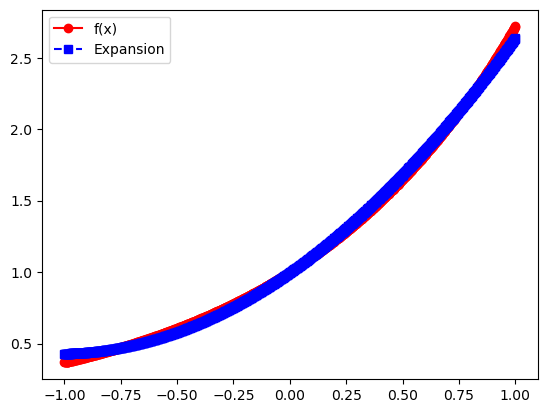

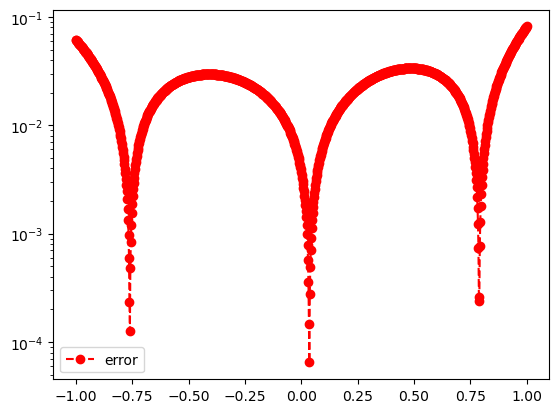

In [34]:
driver()

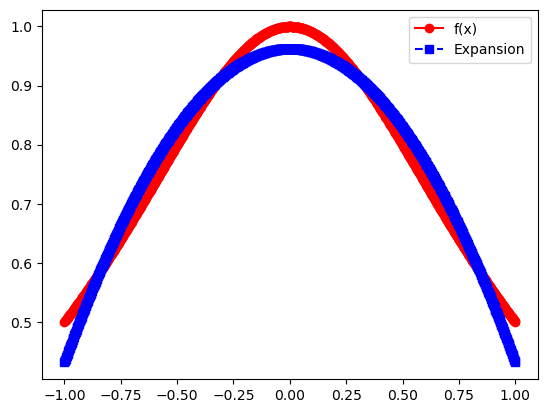

Max error: 0.06858347057703468


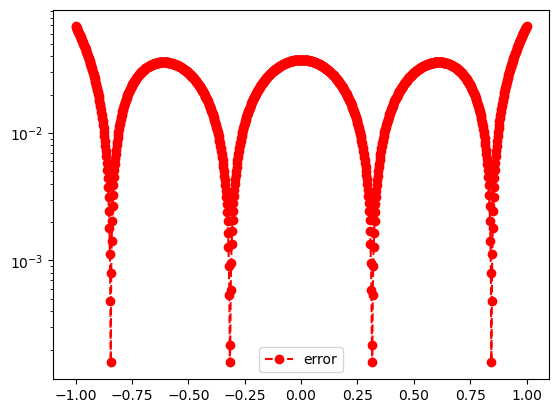

In [56]:
driver()

Judging by the scale of the error plot, the approximation for the $\frac{1}{1+x^2}$ is marginally better than the approximation for $e^x$.

In [48]:
def eval_cheby(n, x):

    if n < 0:
        raise ValueError("Order n must be a non-negative integer.")
    
    t = [0.0] * (n + 1)
    
    t[0] = 1.0
    if n == 0:
        return t
        
    t[1] = x
    
    for k in range(1, n):
        t[k + 1] = 2*x*t[k] - t[k-1]
        
    return t

In [57]:
def driver_cheby():

#  function you want to approximate
    f = lambda x: 1/(1+(x**2))

# Interval of interest    
    a = -1
    b = 1
# weight function    
    w = lambda x: 1 / (np.sqrt(1-(x**2)))

# order of approximation
    n = 2

#  Number of points you want to sample in [a,b]
    N = 1000
    xeval = np.linspace(a,b,N+1)
    pval = np.zeros(N+1)

    for kk in range(N+1):
      pval[kk] = eval_cheby_expansion(f,a,b,w,n,xeval[kk])
      
    ''' create vector with exact values'''
    fex = np.zeros(N+1)
    for kk in range(N+1):
        fex[kk] = f(xeval[kk])
        
    plt.figure()    
    plt.plot(xeval,fex,'ro-', label= 'f(x)')
    plt.plot(xeval,pval,'bs--',label= 'Expansion') 
    plt.legend()
    plt.show()    
    
    err = abs(pval-fex)
    print("Max error:", max(err))
    plt.semilogy(xeval,err,'ro--',label='error')
    plt.legend()
    plt.show()


In [40]:
def eval_cheby_expansion(f,a,b,w,n,x): 

#   This subroutine evaluates the Legendre expansion

#  Evaluate all the Legendre polynomials at x that are needed
# by calling your code from prelab 
  p = eval_cheby(n, x)

  # initialize the sum to 0 
  pval = 0.0    

  for j in range(0,n+1):
      # make a function handle for evaluating phi_j(x)
      phi_j = lambda x: eval_cheby(j,x)[j]

      # make a function handle for evaluating phi_j^2(x)*w(x)
      phi_j_sq = lambda x: phi_j(x)**2 * w(x)

      # use the quad function from scipy to evaluate normalizations
      norm_fac,err = quad(phi_j_sq, a, b)

      # make a function handle for phi_j(x)*f(x)*w(x)/norm_fac
      func_j = lambda x: (phi_j(x) * f(x) * w(x))/norm_fac

      # use the quad function from scipy to evaluate coeffs
      aj,err = quad(func_j, a, b)

      # accumulate into pval
      pval = pval+aj*p[j] 
       
  return pval

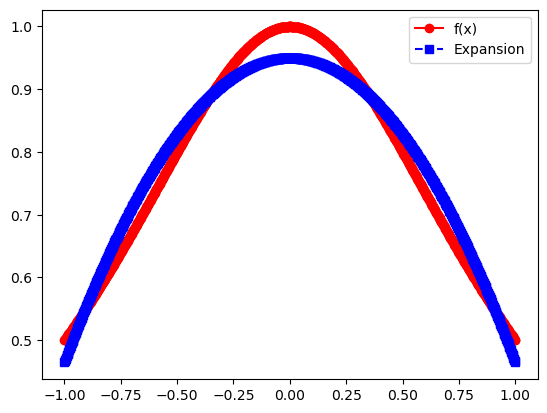

Max error: 0.05025253169412569


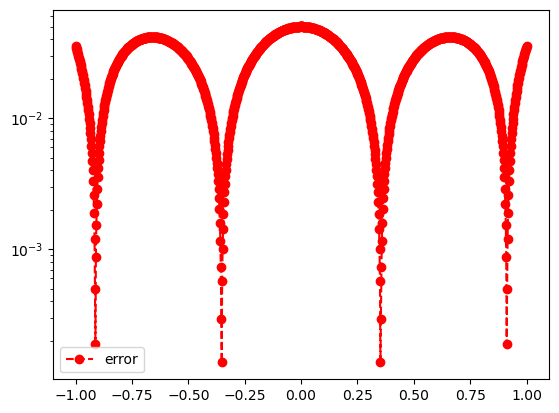

In [58]:
driver_cheby()

The Chebyshev plots look similar to the Legendre polynomials but the max error (0.05025253169412569) is smaller than the max error for Legendre (0.06858347057703468).